# Desigualdades de Markov, Chebyshev y Chernoff

**Objetivo.** Obtener cotas para eventos extremos sin calcular necesariamente toda la distribución y comparar su precisión para variables Poisson y exponenciales.

## 1. Preparación del entorno

El bloque funciona al abrir Jupyter desde la raíz o desde `notebooks/`.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
from funciones.cotas import comparar_exponencial, comparar_poisson
from funciones.visualizacion import graficar_comparacion
pd.options.display.float_format = '{:.6g}'.format
plt.style.use('seaborn-v0_8-whitegrid')

## 2. Desigualdad de Markov

**Teorema.** Si $X\ge 0$ casi seguramente y $a>0$, entonces

$$\mathbb P(X\ge a)\le \frac{\mathbb E[X]}{a}.$$

**Demostración.** Para todo resultado $\omega$,

$$X(\omega)\ge a\,\mathbf 1_{\{X\ge a\}}(\omega).$$

Al tomar esperanzas y usar monotonía,

$$\mathbb E[X]\ge a\,\mathbb E[\mathbf 1_{\{X\ge a\}}]=a\,\mathbb P(X\ge a).$$

Dividir entre $a>0$ prueba el resultado. $\square$

## 3. Desigualdad de Chebyshev

Si $X$ tiene media $\mu$ y varianza finita $\sigma^2$, para $t>0$,

$$\mathbb P(|X-\mu|\ge t)\le \frac{\sigma^2}{t^2}.$$

**Demostración.** $Y=(X-\mu)^2$ es no negativa. Markov con umbral $t^2$ implica

$$\mathbb P(|X-\mu|\ge t)=\mathbb P((X-\mu)^2\ge t^2)\le\frac{\mathbb E[(X-\mu)^2]}{t^2}=\frac{\operatorname{Var}(X)}{t^2}.\quad\square$$

Para $a>\mu$, $\{X\ge a\}\subseteq\{|X-\mu|\ge a-\mu\}$, así que

$$\mathbb P(X\ge a)\le\frac{\sigma^2}{(a-\mu)^2}.$$

Esta versión procede de una cota bilateral y puede ser conservadora para una sola cola.

## 4. Cota de Chernoff

La función generadora de momentos es $M_X(\theta)=\mathbb E[e^{\theta X}]$ donde sea finita. Para $\theta>0$, la exponencial es creciente y Markov da

$$\mathbb P(X\ge a)=\mathbb P(e^{\theta X}\ge e^{\theta a})\le e^{-\theta a}M_X(\theta).$$

Al optimizar entre los valores admisibles,

$$\mathbb P(X\ge a)\le \inf_{\theta>0}e^{-\theta a}M_X(\theta).$$

Ésta es la cota de Chernoff; incorpora más información de la distribución mediante la MGF.

## 5. Funciones generadoras de momentos

### Poisson

Si $X\sim\operatorname{Poisson}(\lambda)$,

$$M_X(\theta)=\sum_{j=0}^{\infty}e^{\theta j}e^{-\lambda}\frac{\lambda^j}{j!}=\exp\{\lambda(e^\theta-1)\},$$

finita para todo $\theta\in\mathbb R$. Para un entero $k>\lambda$, el óptimo es $\theta^*=\log(k/\lambda)$ y

$$\mathbb P(X\ge k)\le e^{-\lambda}\left(\frac{e\lambda}{k}\right)^k.$$

### Exponencial

Para $Y\sim\operatorname{Exp}(\lambda)$ con **tasa** $\lambda$ (escala $1/\lambda$),

$$M_Y(\theta)=\int_0^\infty e^{\theta y}\lambda e^{-\lambda y}\,dy=\frac{\lambda}{\lambda-\theta},\qquad \theta<\lambda.$$

Si $a>1/\lambda$, el óptimo es $\theta^*=\lambda-1/a$ y

$$\mathbb P(Y\ge a)\le \lambda a\,e^{1-\lambda a}.$$

## 6. Experimento con Poisson

Aquí $\mathbb E[X]=\operatorname{Var}(X)=\lambda$. Para el entero $k$, `poisson.sf(k - 1, mu=lambda)` calcula exactamente $\mathbb P(X\ge k)`. Elegimos umbrales mayores que la media.

In [2]:
lambda_poisson = 5
umbrales_poisson = np.arange(6, 21)
tabla_poisson = comparar_poisson(lambda_poisson, umbrales_poisson)
tabla_poisson[['umbral', 'exacta', 'Markov', 'Chebyshev', 'Chernoff']]

,umbral,exacta,Markov,Chebyshev,Chernoff
0,6,0.384039,0.833333,5,0.910347
1,7,0.237817,0.714286,1.25,0.700959
2,8,0.133372,0.625,0.555556,0.467653
3,9,0.0680936,0.555556,0.3125,0.275249
4,10,0.0318281,0.5,0.2,0.144935
5,11,0.0136953,0.454545,0.138889,0.0690426
6,12,0.00545309,0.416667,0.102041,0.030028
7,13,0.00201885,0.384615,0.078125,0.0120144
8,14,0.00069799,0.357143,0.0617284,0.0044508
9,15,0.000226254,0.333333,0.05,0.00153506


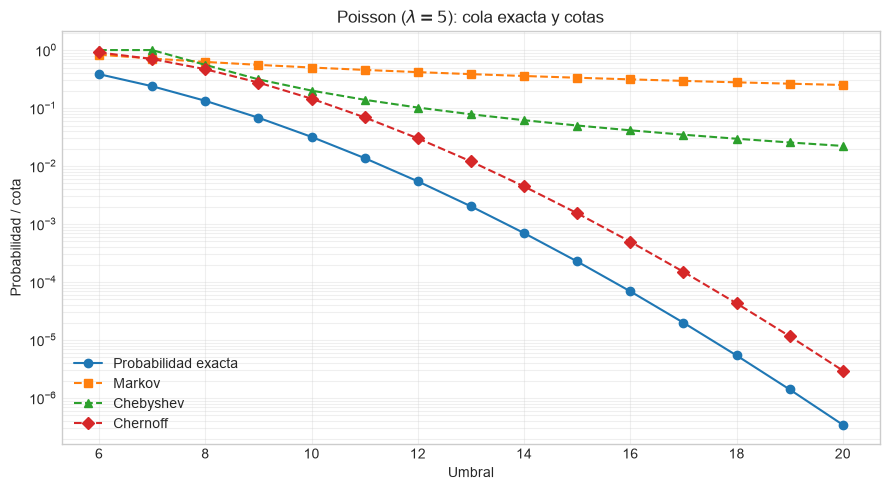

In [3]:
graficar_comparacion(tabla_poisson, rf'Poisson ($\lambda={lambda_poisson}$): cola exacta y cotas');
plt.show()

En la gráfica se usa $\min(1,\text{cota})$, pues una probabilidad no supera uno. La tabla conserva las fórmulas originales: una cota mayor que uno es válida, pero no informativa. La escala logarítmica permite distinguir mejor las colas pequeñas.

## 7. Experimento con la exponencial

Para la parametrización por tasa, $\mathbb E[Y]=1/\lambda$, $\operatorname{Var}(Y)=1/\lambda^2$ y la cola exacta es $e^{-\lambda a}$. En SciPy se debe indicar `scale=1/lambda`.

In [4]:
lambda_exponencial = 2
media_exponencial = 1 / lambda_exponencial
umbrales_exponencial = media_exponencial * np.linspace(1.25, 8, 16)
tabla_exponencial = comparar_exponencial(lambda_exponencial, umbrales_exponencial)
tabla_exponencial[['umbral', 'exacta', 'Markov', 'Chebyshev', 'Chernoff']]

,umbral,exacta,Markov,Chebyshev,Chernoff
0,0.625,0.286505,0.8,16,0.973501
1,0.85,0.182684,0.588235,2.04082,0.844195
2,1.075,0.116484,0.465116,0.756144,0.680769
3,1.3,0.0742736,0.384615,0.390625,0.524931
4,1.525,0.0473589,0.327869,0.237954,0.392641
5,1.75,0.0301974,0.285714,0.16,0.287297
6,1.975,0.0192547,0.253165,0.11491,0.206742
7,2.2,0.0122773,0.227273,0.0865052,0.146842
8,2.425,0.00782838,0.206186,0.067465,0.103207
9,2.65,0.00499159,0.188679,0.0540833,0.0719134


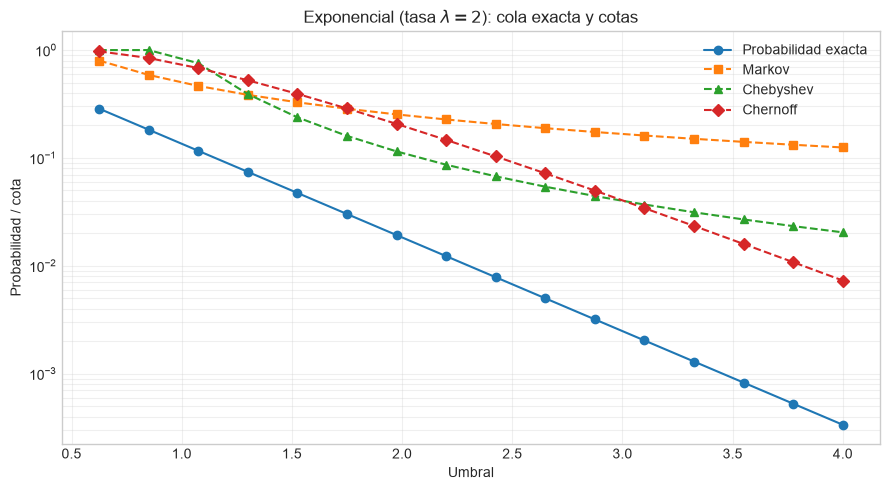

In [5]:
graficar_comparacion(tabla_exponencial, rf'Exponencial (tasa $\lambda={lambda_exponencial}$): cola exacta y cotas');
plt.show()

## 8. Variación de $\lambda$

Comparamos umbrales como múltiplos de la media. Para Poisson se redondean hacia arriba por ser una distribución discreta.

In [6]:
factores = np.array([1.5, 2, 3, 4])
tablas = []
for lam in [2, 5, 10]:
    k = np.unique(np.ceil(lam * factores).astype(int))
    tablas.append(comparar_poisson(lam, k[k > lam]))
for lam in [0.5, 1, 2]:
    tablas.append(comparar_exponencial(lam, factores / lam))
resumen = pd.concat(tablas, ignore_index=True)
resumen[['distribucion', 'umbral', 'exacta', 'Markov', 'Chebyshev', 'Chernoff']]

,distribucion,umbral,exacta,Markov,Chebyshev,Chernoff
0,Poisson(lambda=2),3,0.323324,0.666667,2,0.805417
1,Poisson(lambda=2),4,0.142877,0.5,0.5,0.461816
2,Poisson(lambda=2),6,0.0165636,0.333333,0.125,0.0748946
3,Poisson(lambda=2),8,0.00109672,0.25,0.0555556,0.00615583
4,Poisson(lambda=5),8,0.133372,0.625,0.555556,0.467653
5,Poisson(lambda=5),10,0.0318281,0.5,0.2,0.144935
6,Poisson(lambda=5),15,0.000226254,0.333333,0.05,0.00153506
7,Poisson(lambda=5),20,3.45214e-07,0.25,0.0222222,2.97315e-06
8,Poisson(lambda=10),15,0.0834585,0.666667,0.4,0.338925
9,Poisson(lambda=10),20,0.00345434,0.5,0.1,0.0210061


In [7]:
columnas = ['Markov_info', 'Chebyshev_info', 'Chernoff_info']
assert resumen[columnas].ge(resumen['exacta'], axis=0).all().all()
print('Verificación superada: todas las cotas dominan las probabilidades exactas.')

Verificación superada: todas las cotas dominan las probabilidades exactas.


## 9. Conclusiones

1. **Markov** sólo requiere no negatividad y la media, pero suele ser la cota más holgada.
2. **Chebyshev** añade la varianza. Cerca de la media puede exceder uno; para ciertos umbrales mejora a Markov, aunque ignora la forma de la cola.
3. **Chernoff** usa la MGF y un parámetro optimizado. Captura el decaimiento exponencial y suele ser más ajustada para eventos extremos.
4. Las cotas no tienen que coincidir con la probabilidad exacta: son especialmente útiles cuando calcular toda la distribución es difícil.
5. Para la exponencial, Chernoff difiere de la cola exacta por el factor $e\lambda a$; para Poisson captura el orden exponencial de las desviaciones grandes.

## Referencias

- Ross, S. M. (2014). *A First Course in Probability* (9th ed.). Pearson.
- Mitzenmacher, M., & Upfal, E. (2017). *Probability and Computing* (2nd ed.). Cambridge University Press.
- SciPy Community. Documentación de `scipy.stats.poisson` y `scipy.stats.expon`.